# EDA - home advantage across 10 Premier League seasons (Lu)

I use Nate's `epl_data.csv` for 2016/17-2023/24, Youssef's `football_matches_2024_2025.csv` for 2024/25 and my `E0.csv` for 2025/26.

In [205]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Nate's file has one row per team per season, so first I checked that every team played 38 games.

In [206]:
history = pl.read_csv("data/epl_data.csv")

(history.filter(pl.col("season") >= 2016)
    .group_by("season")
    .agg(min_games=pl.col("matches_played").min(),
         max_games=pl.col("matches_played").max())
    .sort("season"))

season,min_games,max_games
i64,i64,i64
2016,38,38
2017,38,38
2018,38,38
2019,38,38
2020,38,38
2021,38,38
2022,38,38
2023,38,38
2024,19,20


2024 only has 19-20 games per team (looks like it was scraped mid season), so I left it out and used Youssef's full 2024/25 season instead.

Youssef's data writes results as "Home Win" etc., so I changed it to H / D / A like `E0.csv` so both can go through the same function. For Nate's data, adding up `home_matches_draw` gives the number of drawn matches since each match has one home team.

In [207]:
def count_results(df, season, source):
    return df.select(
        season=pl.lit(season),
        matches=pl.len(),
        home_wins=(pl.col("FTR") == "H").sum(),
        draws=(pl.col("FTR") == "D").sum(),
        away_wins=(pl.col("FTR") == "A").sum(),
        source=pl.lit(source),
    )

nate = (history.filter(pl.col("season").is_between(2016, 2023))
    .group_by("season")
    .agg(matches=(pl.col("matches_played").sum() / 2).cast(pl.Int64),
         home_wins=pl.col("home_matches_win").sum(),
         draws=pl.col("home_matches_draw").sum(),
         away_wins=pl.col("away_matches_win").sum())
    .with_columns(source=pl.lit("epl_data.csv")))

youssef = (pl.read_csv("data/football_matches_2024_2025.csv")
    .filter(pl.col("competition_name") == "Premier League")
    .with_columns(FTR=pl.col("match_outcome").replace({"Home Win": "H", "Draw": "D", "Away Win": "A"})))

seasons = (pl.concat([nate,
                      count_results(youssef, 2024, "football_matches_2024_2025.csv"),
                      count_results(pl.read_csv("data/E0.csv"), 2025, "E0.csv")],
                     how="vertical_relaxed")
    .with_columns(
        label=pl.col("season").cast(pl.String) + "/" + ((pl.col("season") + 1) % 100).cast(pl.String).str.zfill(2),
        home_win_pct=(100 * pl.col("home_wins") / pl.col("matches")).round(1),
        draw_pct=(100 * pl.col("draws") / pl.col("matches")).round(1),
        away_win_pct=(100 * pl.col("away_wins") / pl.col("matches")).round(1))
    .sort("season"))

seasons.select("label", "matches", "home_win_pct", "draw_pct", "away_win_pct", "source")

label,matches,home_win_pct,draw_pct,away_win_pct,source
str,i64,f64,f64,f64,str
"""2016/17""",380,49.2,22.1,28.7,"""epl_data.csv"""
"""2017/18""",380,45.5,26.1,28.4,"""epl_data.csv"""
"""2018/19""",380,47.6,18.7,33.7,"""epl_data.csv"""
"""2019/20""",380,45.3,24.2,30.5,"""epl_data.csv"""
"""2020/21""",380,37.9,21.8,40.3,"""epl_data.csv"""
"""2021/22""",380,42.9,23.2,33.9,"""epl_data.csv"""
"""2022/23""",380,48.4,22.9,28.7,"""epl_data.csv"""
"""2023/24""",380,46.1,21.6,32.4,"""epl_data.csv"""
"""2024/25""",380,40.8,24.5,34.7,"""football_matches_2024_2025.csv"""


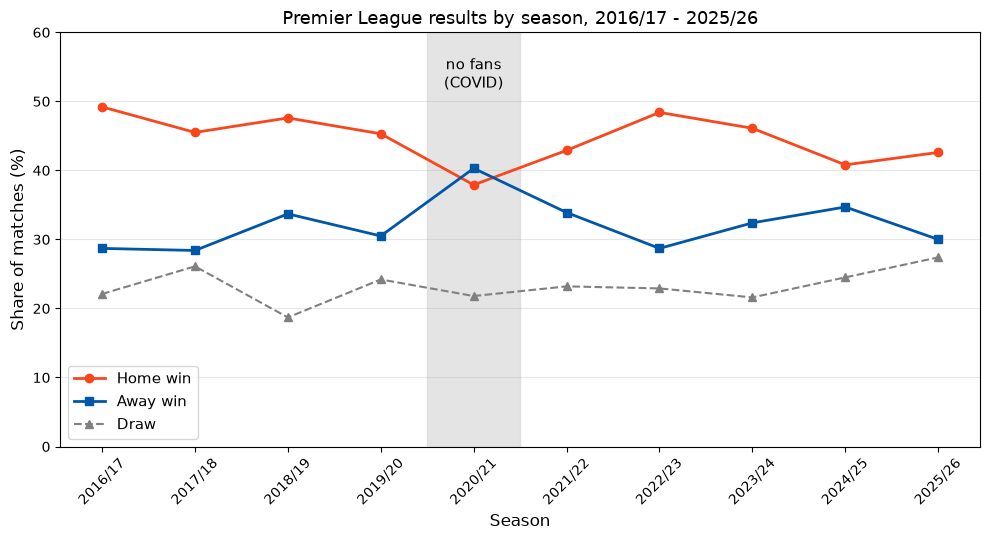

In [208]:
fig, ax = plt.subplots(figsize=(10, 5.5))

x = seasons["season"].to_list()
ax.axvspan(2019.5, 2020.5, color="lightgrey", alpha=0.6)
ax.text(2020, 52, "no fans\n(COVID)", ha="center", fontsize=11)

ax.plot(x, seasons["home_win_pct"], marker="o", color="#f9461c", linewidth=2, label="Home win")
ax.plot(x, seasons["away_win_pct"], marker="s", color="#0057a8", linewidth=2, label="Away win")
ax.plot(x, seasons["draw_pct"], marker="^", color="grey", linewidth=1.5, linestyle="--", label="Draw")

ax.set_xticks(x)
ax.set_xticklabels(seasons["label"].to_list(), rotation=45)
ax.set_ylim(0, 60)
ax.set_xlabel("Season", fontsize=12)
ax.set_ylabel("Share of matches (%)", fontsize=12)
ax.set_title("Premier League results by season, 2016/17 - 2025/26", fontsize=13)
ax.legend(fontsize=11, loc="lower left")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Each point is one full season (380 matches). The grey band is 2020/21, played without fans.

**So what?** In 9 of 10 seasons home teams won more than away teams (home win about 41-49%, away win about 28-35%). 2020/21 is the only season where the lines cross: away teams won 40.3% and home teams 37.9%. Once fans came back home wins went up again (42.9% in 2021/22, 48.4% in 2022/23), which fits the idea that fans are part of home advantage.

**Expected?** Partly. I expected home advantage to shrink without fans, but not to flip. Seasons with fans also move around more than I thought (40.8% in 2024/25 vs 48.4% in 2022/23).

**What next?** 2020/21 was weird in other ways too (packed schedule, no preseason), so this doesn't prove fans cause it; comparing other leagues that played without fans would help. The last 92 matches of 2019/20 were also behind closed doors but are hidden in Nate's season totals. Also, Dominic's and my files have cards and fouls, so I want to check if referees treated home teams differently without fans.

## Anomalies

| anomaly | rows affected | what I did |
|---|---|---|
| `epl_data.csv` 2024 season is only half a season (199 matches instead of 380) | 20 rows | left out, used Youssef's 2024/25 instead |
| season and result are coded differently in each file | all rows | made one `season` column (start year) and changed results to H / D / A |
| 2019/20 has 92 no-fans matches inside the season total | 92 matches | flagged, can't split them with season totals |

I also checked 2020/21 against Dominic's match-by-match `epl_2020.csv` and got the same counts (144 / 83 / 153).

**Revised question:** does home advantage shrink or disappear without fans, and does it come back when they return?

## Feature Distributions: Visualizing the Home Advantage (Dominic)

To understand the baseline home advantage, we need to look at the distribution of our primary features: Match Outcomes, Goals Scored, and Shot Generation.

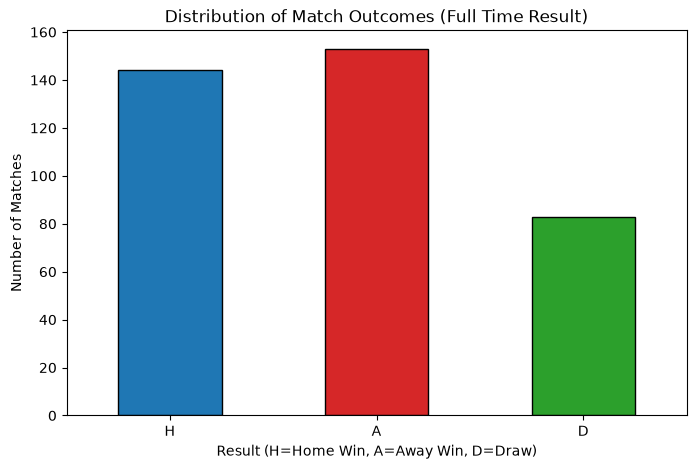

In [209]:
df = pd.read_csv('data/epl_2020.csv')
# Plotting Full Time Result
plt.figure(figsize=(8, 5))

outcome_counts = df['FTR'].value_counts()[['H', 'A', 'D']]
outcome_counts.plot(kind='bar', color=['#1f77b4', '#d62728', '#2ca02c'], edgecolor='black')

plt.title('Distribution of Match Outcomes (Full Time Result)')
plt.xlabel('Result (H=Home Win, A=Away Win, D=Draw)')
plt.ylabel('Number of Matches')
plt.xticks(rotation=0)
plt.show()

**Description: Match Outcomes (FTR) - 2020 "Ghost Games" Season**
* **Center (Mode):** The mode of this distribution is 'A' (Away Win), which is unusual for a standard soccer season.
* **Spread:** Away wins are the most frequent outcome, followed closely by Home wins ('H'), with Draws ('D') being the least common.
* **Takeaway:** This inverted distribution shows our primary research question. During the 2020 season played without fans in the stadiums, the traditional "home-field advantage" disappeared, resulting in a higher rate of away victories.

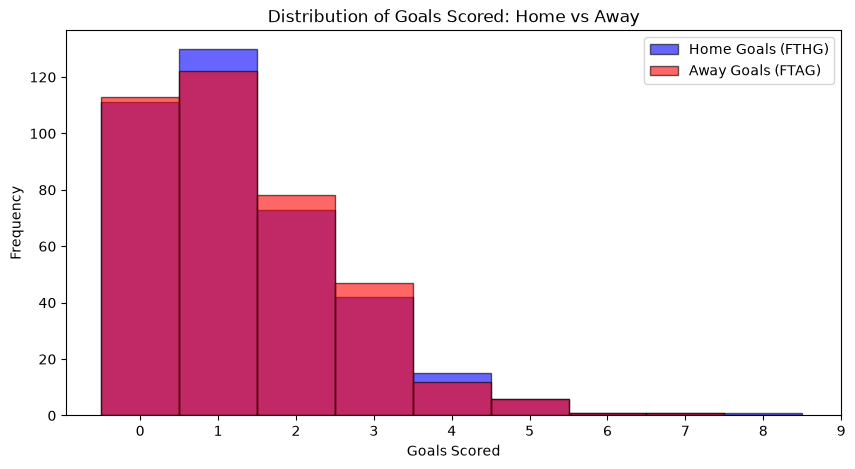

Home Goals Stats:
 count    380.000000
mean       1.352632
std        1.320378
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        9.000000
Name: FTHG, dtype: float64 

Away Goals Stats:
 count    380.000000
mean       1.342105
std        1.257722
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        7.000000
Name: FTAG, dtype: float64


In [210]:
# Plotting Goals Scored (FTHG vs FTAG)
plt.figure(figsize=(10, 5))

plt.hist(df['FTHG'], bins=range(0, 10), alpha=0.6, label='Home Goals (FTHG)', color='blue', align='left', edgecolor='black')
plt.hist(df['FTAG'], bins=range(0, 10), alpha=0.6, label='Away Goals (FTAG)', color='red', align='left', edgecolor='black')

plt.title('Distribution of Goals Scored: Home vs Away')
plt.xlabel('Goals Scored')
plt.ylabel('Frequency')
plt.xticks(range(0, 10))
plt.legend()
plt.show()

print("Home Goals Stats:\n", df['FTHG'].describe(), "\n")
print("Away Goals Stats:\n", df['FTAG'].describe())

**Description: Goals Scored (FTHG vs FTAG) **
* **Shape & Skew:** This distributions is heavily right-skewed. The bulk of the data falls between 0 and 2 goals.
* **Center:** Unlike a normal season, the distributions are nearly identical with massive overlap. The mean for Home Goals is *not* visibly shifted higher; in fact, Away teams scored 2 and 3 goals more frequently than Home teams in this dataset. 
* **Spread:** The vast majority of team performances result in 0 to 3 goals.
* **Outliers:** There is a long right tail containing outliers for both sides, representing rare blowout matches where a team scores 4 to 8 goals.
* **Takeaway:** The lack of a distinct, right-shifted scoring advantage for the home team  aligns with the inverted match outcomes in the previous plot, showing how the absence of fans neutralized the home offensive advantage.

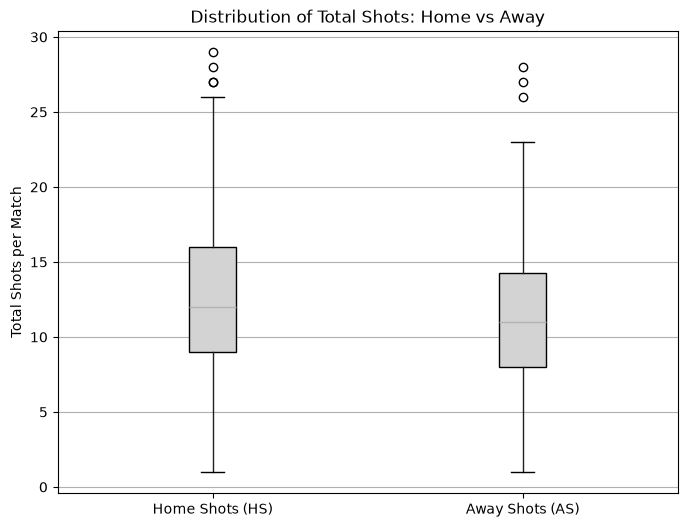

               HS          AS
count  380.000000  380.000000
mean    12.815789   11.363158
std      5.490482    4.880602
min      1.000000    1.000000
25%      9.000000    8.000000
50%     12.000000   11.000000
75%     16.000000   14.250000
max     29.000000   28.000000


In [211]:
# Plotting Shots Taken (HS vs AS)
plt.figure(figsize=(8, 6))

df.boxplot(column=['HS', 'AS'], patch_artist=True, boxprops=dict(facecolor='lightgray'))

plt.title('Distribution of Total Shots: Home vs Away')
plt.ylabel('Total Shots per Match')
plt.xticks([1, 2], ['Home Shots (HS)', 'Away Shots (AS)'])
plt.grid(False, axis='x') # Clean up vertical grid lines
plt.show()

print(df[['HS', 'AS']].describe())

**Description: Shot Generation (HS vs AS)**
* **Shape & Skew:** Both distributions are slightly right-skewed but resemble a more normal, bell-shaped distribution compared to actual goals scored. 
* **Center:** The median number of shots for the Home team is slightly higher compared to the Away team. 
* **Spread :** The middle 50% of home performances generate significantly more offensive pressure than away performances.
* **Outliers:** Both distributions feature upper-bound outliers, representing extreme anomalies where a team registers an unusually high number of shots in a single match.

# International results (Hannan)

   I use `results.csv` (49,547 men's international matches, 1872–2026) to compare home games with
neutral-venue games.

Checkpoint 3:

#6

In [212]:
   intl = pl.read_csv("data/results.csv", try_parse_dates=True)

In [213]:
print(intl.shape)
intl.glimpse()
print(intl.null_count())
intl.describe()


(49547, 9)
Rows: 49547
Columns: 9
$ date       <date> 1872-11-30, 1873-03-08, 1874-03-07, 1875-03-06, 1876-03-04, 1876-03-25, 1877-03-03, 1877-03-05, 1878-03-02, 1878-03-23
$ home_team   <str> 'Scotland', 'England', 'Scotland', 'England', 'Scotland', 'Scotland', 'England', 'Wales', 'Scotland', 'Scotland'
$ away_team   <str> 'England', 'Scotland', 'England', 'Scotland', 'England', 'Wales', 'Scotland', 'Scotland', 'England', 'Wales'
$ home_score  <i64> 0, 4, 2, 2, 3, 4, 1, 0, 7, 9
$ away_score  <i64> 0, 2, 1, 2, 0, 0, 3, 2, 2, 0
$ tournament  <str> 'Friendly', 'Friendly', 'Friendly', 'Friendly', 'Friendly', 'Friendly', 'Friendly', 'Friendly', 'Friendly', 'Friendly'
$ city        <str> 'Glasgow', 'London', 'Glasgow', 'London', 'Glasgow', 'Glasgow', 'London', 'Wrexham', 'Glasgow', 'Glasgow'
$ country     <str> 'Scotland', 'England', 'Scotland', 'England', 'Scotland', 'Scotland', 'England', 'Wales', 'Scotland', 'Scotland'
$ neutral    <bool> False, False, False, False, False, False, False, 

statistic,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
str,str,str,str,f64,f64,str,str,str,f64
"""count""","""49547""","""49547""","""49547""",49547.0,49547.0,"""49547""","""49547""","""49547""",49547.0
"""null_count""","""0""","""0""","""0""",0.0,0.0,"""0""","""0""","""0""",0.0
"""mean""","""1994-06-07 16:43:07.216178""",null,null,1.75714,1.182715,null,null,null,0.265566
"""std""",null,null,null,1.773702,1.402353,null,null,null,null
"""min""","""1872-11-30""","""Abkhazia""","""Abkhazia""",0.0,0.0,"""ABCS Tournament""","""6th of October City""","""Afghanistan""",0.0
"""25%""","""1980-09-18""",null,null,1.0,0.0,null,null,null,null
"""50%""","""2000-07-28""",null,null,1.0,1.0,null,null,null,null
"""75%""","""2013-08-14""",null,null,2.0,2.0,null,null,null,null
"""max""","""2026-08-26""","""Åland Islands""","""Åland Islands""",31.0,21.0,"""Évence Coppée Trophy""","""‘Atele""","""Éire""",1.0


This dataset has 49,547 rows and 9 columns, and no missing values. We can see that the scoring median is 1 goal for each side, but that is stretched by the max being 31 for home teams, and 21 for away teams. Home teams average 1.76 goals a game, compared to 1.18 for away teams. And this shows a bit of an advantage for home teams already. 

Step 7: Anomalies

In [214]:
intl.filter(pl.struct("date","home_team", "away_team").is_duplicated())


date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
date,str,str,i64,i64,str,str,str,bool
1974-02-17,"""Tahiti""","""New Caledonia""",2,1,"""Friendly""","""Papeete""","""Tahiti""",false
1974-02-17,"""Tahiti""","""New Caledonia""",1,2,"""Friendly""","""Papeete""","""Tahiti""",false


In [215]:
intl.filter(~pl.col("neutral") & (pl.col("home_team") != pl.col("country"))).height

979

In [216]:
intl.filter((pl.col("home_score") - pl.col("away_score")).abs() >= 10).height

268

In [217]:
print(intl["tournament"].n_unique())

intl = intl.with_columns(
    pl.when(pl.col("tournament") == "Friendly").then(pl.lit("Friendly")).otherwise(pl.lit("Competetive")).alias("match_type"), (pl.col("home_score") - pl.col("away_score")).alias("goal_diff"),pl.col("date").dt.year().alias("year"),)
                                                                                                                                
    
    

202


The first table shows that there are 2 rows which share the same date and teams, but they have different scores, so it is probably two matches played on the same day. 

The second number: 979, shows the home matches which list a country that doesn't match the home team's name. I think we can use the neutral column to reliably check and differentiate home games from neutral ones.

The third number just shows some of the more extreme results, so there are 268 matches won by 10 or more goals.

The fourth number, 202, shows the different tournament names, which might be too many to compare, so we can group them by friendly and competitivee typee.


Step 8: Distributions:

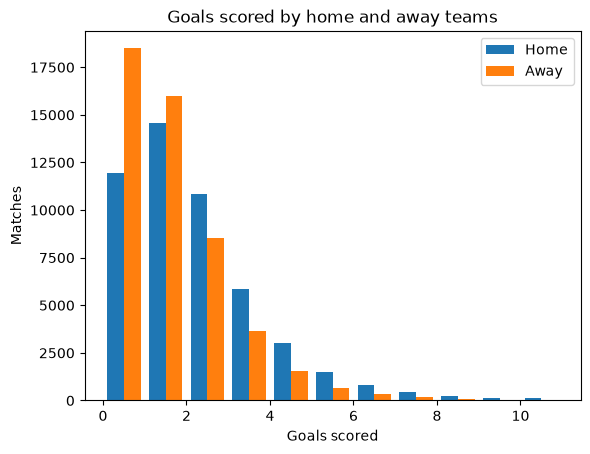

In [218]:
fig, ax = plt.subplots()
ax.hist([intl["home_score"], intl["away_score"]], bins=range(0, 12), label=["Home", "Away"])
ax.set_xlabel("Goals scored"); ax.set_ylabel("Matches"); ax.legend()
ax.set_title("Goals scored by home and away teams")
plt.show()

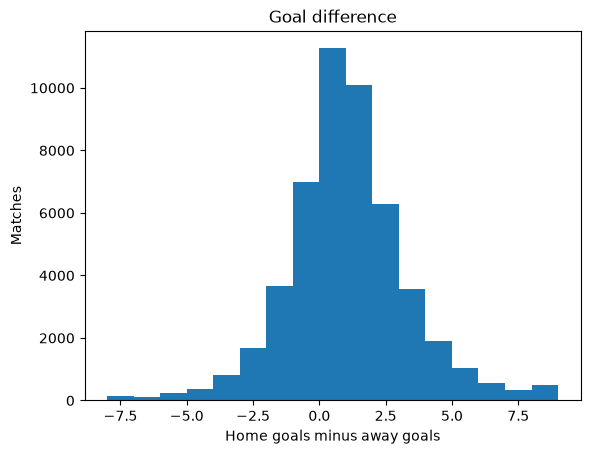

In [219]:
fig, ax = plt.subplots()
ax.hist(intl["goal_diff"].clip(-8, 8), bins=range(-8, 10))
ax.set_xlabel("Home goals minus away goals"); ax.set_ylabel("Matches")
ax.set_title("Goal difference")
plt.show()

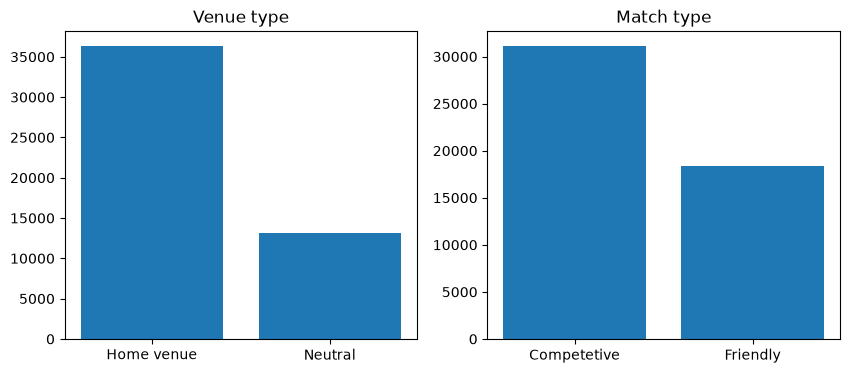

In [220]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
v = intl["neutral"].value_counts().sort("neutral")
axes[0].bar(["Home venue", "Neutral"], v["count"])
axes[0].set_title("Venue type")
m = intl["match_type"].value_counts()
axes[1].bar(m["match_type"], m["count"])
axes[1].set_title("Match type")
plt.show()

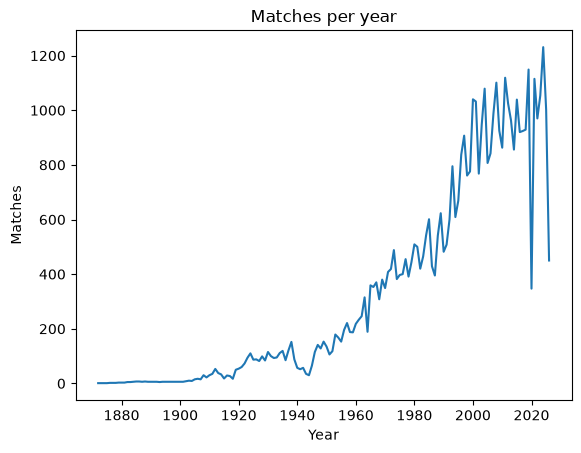

In [221]:
per_year = intl.group_by("year").len().sort("year")
fig, ax = plt.subplots()
ax.plot(per_year["year"], per_year["len"])
ax.set_xlabel("Year"); ax.set_ylabel("Matches"); ax.set_title("Matches per year")
plt.show()

The first figure shows that most teams score between 0 and 2 goals. And the teams to most often score 0, are away times. The home teams distribution sits further to the right, with both have some high scoring games. 

The second figure shows that the goal differnce is centered just a little above 0 goals. We can also see that the shape is almost symmetrical, though we can see that th4 home teams win by more goals. 

The third figure shows that most of the matches are played in the home venue compared to a neutral venue. And we can also see that there are considerably more competetive games that friendly games.

The fourth figure shows the amount of matches played per year. We can see that there are very few matches played before the 1920s, with a lot more being played after the 1980s. There are a few dips closer to 2020, which might be explained by the pandemic.

9: Relationships

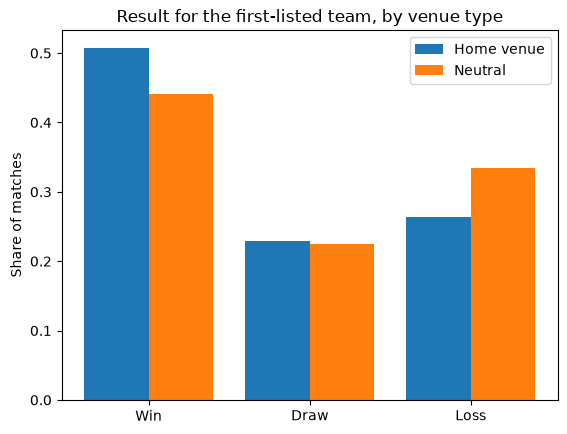

In [222]:
res = intl.with_columns(
    pl.when(pl.col("goal_diff") > 0).then(pl.lit("Win"))
      .when(pl.col("goal_diff") == 0).then(pl.lit("Draw"))
      .otherwise(pl.lit("Loss")).alias("result")
)
tab = (res.group_by("neutral", "result").len()
          .with_columns((pl.col("len") / pl.col("len").sum().over("neutral")).alias("share")))
fig, ax = plt.subplots()
for i, (label, flag) in enumerate([("Home venue", False), ("Neutral", True)]):
    sub = tab.filter(pl.col("neutral") == flag)
    shares = [sub.filter(pl.col("result") == r)["share"][0] for r in ["Win", "Draw", "Loss"]]
    ax.bar([x + i * 0.4 for x in range(3)], shares, width=0.4, label=label)
ax.set_xticks([0.2, 1.2, 2.2], ["Win", "Draw", "Loss"])
ax.set_ylabel("Share of matches"); ax.legend()
ax.set_title("Result for the first-listed team, by venue type")
plt.show()

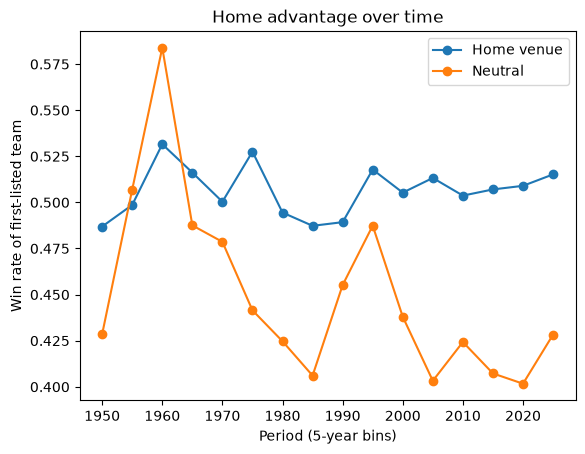

In [223]:
trend = (res.filter(pl.col("year") >= 1950)
            .with_columns((pl.col("year") // 5 * 5).alias("period"))
            .group_by("period", "neutral")
            .agg((pl.col("goal_diff") > 0).mean().alias("win_rate"))
            .sort("period"))
fig, ax = plt.subplots()
for label, flag in [("Home venue", False), ("Neutral", True)]:
    s = trend.filter(pl.col("neutral") == flag)
    ax.plot(s["period"], s["win_rate"], marker="o", label=label)
ax.set_xlabel("Period (5-year bins)"); ax.set_ylabel("Win rate of first-listed team")
ax.legend(); ax.set_title("Home advantage over time")
plt.show()

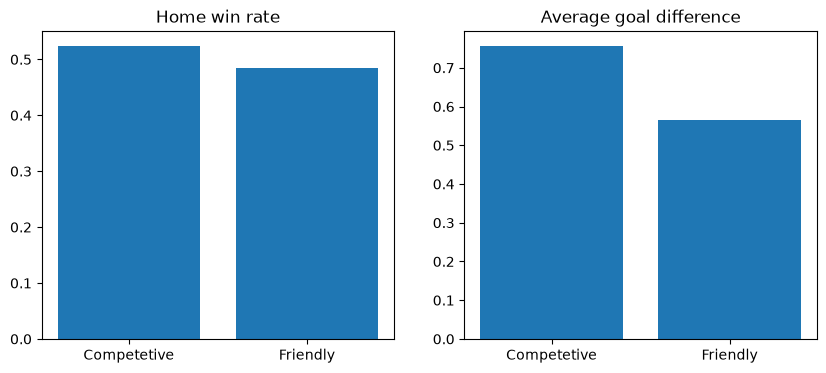

In [224]:
comp = (res.filter(~pl.col("neutral"))
           .group_by("match_type")
           .agg((pl.col("goal_diff") > 0).mean().alias("home_win_rate"),
                pl.col("goal_diff").mean().alias("avg_goal_diff")))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(comp["match_type"], comp["home_win_rate"]); axes[0].set_title("Home win rate")
axes[1].bar(comp["match_type"], comp["avg_goal_diff"]); axes[1].set_title("Average goal difference")
plt.show()

The first plot shows the results by venue type, and we can see that the home team wins slightly above 50 percent of the matches, and looses only about 25 percent of them. At neutral venues the team which is listed first wins about 45 percent of the times, and looses about 30 percent of the times. This is a bit interesting because i would have expected the results to be a bit more in favor of the home teams,, but the draw rate stays pretty flat. Next we should try to do something which can control for team strength, for example we can look at the corresponding fifa rankings.

The second plot shows since 1950s team playing at home generally have won more often than first listed teams at neutral venues. I would have expect that moving forward,  the gap between those should shrink because travel is much easier now, but as we can see that it is actually increasing. Next, I will compare this with the Premier League data set that we chose to see how the club home advantage changed from international games.

The third plot shows the home team win rate, and the average goal difference between friendly and competetive games. As we can see, in competetive games the home teams have a higher win rate vs friendly games. We can also see that the average goal difference in competetive games is noticeably higher than in friendly games. This makes sense to me because I would expect that in competetive games, home teams would have a more pumped up crowd  than in friendly games. Moving forward, we could break down the competetive games into different types, like world cup matches vs continental tournaments.

10: Revised

So our original research question was: How does playing at home affect team performance and match outcomes?

I think with my dataset, I would revise this to: How much does playing at home increase a team's chance of winning compared to a neutral venue, and does this advantage change with match importance over time?

Given my dataset, I would say the comparison between home and neutral venues turned out to be the clearest way to measure home advantage.

## Home vs Away Yellow Card Analysis (2020/21 Premier League) - Nate Rodriguez

This analysis examines differences in yellow cards received by home and away teams during the 2020/21 Premier League season. Matches are grouped into sets of 20 to compare average yellow cards throughout the season and investigate whether playing at home is associated with disciplinary outcomes.


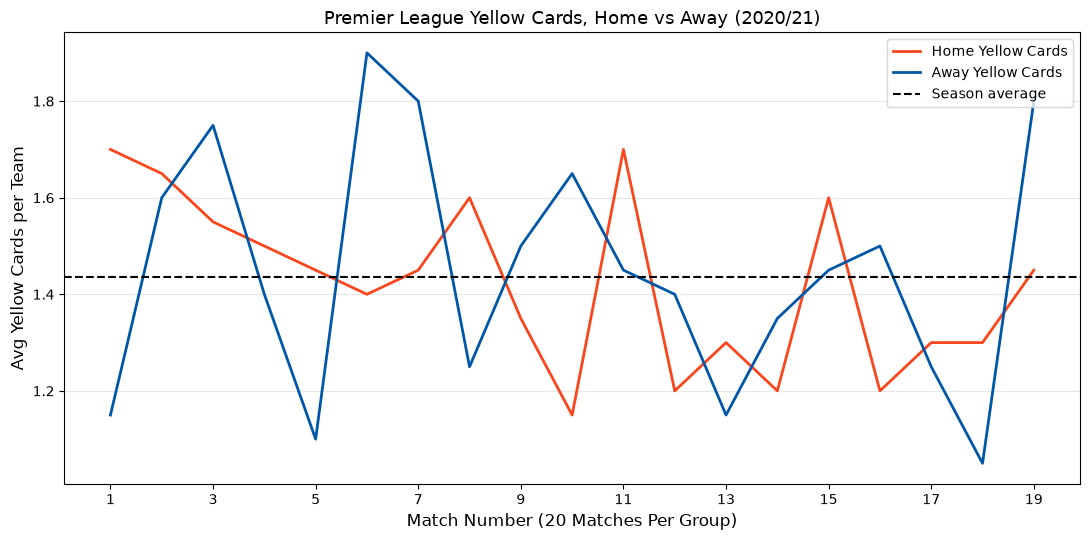

Average Home Yellow Cards: 1.424
Average Away Yellow Cards: 1.447
Combined Average: 1.436
Matches Analyzed: 380


In [225]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

yellow_cards = df[["Date", "HY", "AY"]].dropna().copy()
yellow_cards['Date'] = pd.to_datetime(
    yellow_cards['Date'], dayfirst=True
)

yellow_cards = yellow_cards.sort_values('Date').reset_index(drop=True)

yellow_cards['Group'] = np.arange(len(yellow_cards)) // 20 + 1

grouped = yellow_cards.groupby('Group')[['HY', 'AY']].mean()

home_avg = yellow_cards['HY'].mean()
away_avg = yellow_cards['AY'].mean()
combined_avg = (home_avg + away_avg) / 2

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.plot(grouped.index,
        grouped['HY'],
        color="#f9461c",
        linewidth=2,
        label="Home Yellow Cards"
       )

ax.plot(grouped.index,
        grouped['AY'],
        color="#0057a8",
        linewidth=2,
        label="Away Yellow Cards"
       )

ax.axhline(combined_avg, color="black",
           linewidth=1.5, linestyle="--",
           label="Season average")

ax.set_xlabel("Match Number (20 Matches Per Group)", fontsize=12)
ax.set_ylabel("Avg Yellow Cards per Team", fontsize=12)

ax.set_title("Premier League Yellow Cards, Home vs Away (2020/21)",
             fontsize=13
            )

ax.legend(fontsize=10, loc="upper right")
ax.grid(axis="y", alpha=0.3)

ax.set_xticks(range(1, 20, 2))
plt.tight_layout()
plt.show()



print("Average Home Yellow Cards:", round(home_avg, 3))
print("Average Away Yellow Cards:", round(away_avg, 3))
print("Combined Average:", round(combined_avg, 3))
print("Matches Analyzed:", len(yellow_cards))


**So what?** 
This graph compares the average yellow cards received by home and away teams throughout the 2020/21 Premier League season. Each group represents 20 matches. Home teams average 1.424 yellow cards per match, while away teams average 1.447. The difference is very small, suggesting that playing at home did not have a strong association with the number of yellow cards received during this season. Although the averages fluctuate between match groups, neither home nor away teams consistently received more yellow cards.

**Expected?** 
We expected away teams to receive more yellow cards because home-field advantage could influence referee decisions and disciplinary outcomes. However, the results were somewhat unexpected because the difference between home and away teams was very small. This suggests that yellow-card totals alone may not provide strong enough evidence of home-field advantage during the 2020/21 season.

**What's next?**
Next, we could compare yellow-card averages across multiple Premier League seasons to determine whether the relationship changes when spectators are present. We could also examine the number of fouls committed by home and away teams to see whether differences in yellow cards are related to fouls rather than home-field advantage. This would help us better understand whether playing at home is associated with referee decisions


### Exploratory Data Analysis (EDA): Football Matches 2024–2025 (Youssef)

## 1. Dataset Profile

In [226]:
import pandas as pd

df = pd.read_csv("data/football_matches_2024_2025.csv")

print(df.shape)
df.info()
print(df.isnull().sum())
display(df.describe(include="all"))

(1941, 23)
<class 'pandas.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   competition_code  1941 non-null   str  
 1   competition_name  1941 non-null   str  
 2   season            1941 non-null   str  
 3   match_id          1941 non-null   int64
 4   matchday          1941 non-null   int64
 5   stage             1941 non-null   str  
 6   status            1941 non-null   str  
 7   date_utc          1941 non-null   str  
 8   referee           1941 non-null   str  
 9   home_team_id      1941 non-null   int64
 10  home_team         1941 non-null   str  
 11  away_team_id      1941 non-null   int64
 12  away_team         1941 non-null   str  
 13  fulltime_home     1941 non-null   int64
 14  fulltime_away     1941 non-null   int64
 15  halftime_home     1941 non-null   int64
 16  halftime_away     1941 non-null   int64
 17  goal_difference   1941 non-null  

,competition_code,competition_name,season,match_id,matchday,stage,status,date_utc,referee,home_team_id,...,fulltime_home,fulltime_away,halftime_home,halftime_away,goal_difference,total_goals,match_outcome,home_points,away_points,referee_id
count,1941,1941,1941,1941.000000,1941.000000,1941,1941,1941,1941,1941.000000,...,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941,1941.000000,1941.000000,1941.000000
unique,6,6,1,NaN,NaN,7,2,1109,158,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN
top,PL,Premier League,2024/2025,NaN,NaN,REGULAR_SEASON,FINISHED,2025-01-29 20:00:00+00:00,Michael Oliver,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Home Win,NaN,NaN,NaN
freq,380,380,1941,NaN,NaN,1752,1939,18,34,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,832,NaN,NaN,NaN
mean,NaN,NaN,NaN,502366.762494,17.338485,NaN,NaN,NaN,NaN,483.205564,...,1.535806,1.340031,0.699639,0.588357,0.195775,2.875837,NaN,1.524472,1.236991,65.609995
std,NaN,NaN,NaN,7461.271565,11.056850,NaN,NaN,NaN,NaN,1170.086272,...,1.322829,1.205567,0.860319,0.790438,1.880667,1.693997,NaN,1.331631,1.305615,42.866261
min,NaN,NaN,NaN,497410.000000,0.000000,NaN,NaN,NaN,NaN,2.000000,...,0.000000,0.000000,0.000000,0.000000,-6.000000,0.000000,NaN,0.000000,0.000000,-1.000000
25%,NaN,NaN,NaN,498056.000000,7.000000,NaN,NaN,NaN,NaN,67.000000,...,1.000000,0.000000,0.000000,0.000000,-1.000000,2.000000,NaN,0.000000,0.000000,29.000000
50%,NaN,NaN,NaN,498897.000000,17.000000,NaN,NaN,NaN,NaN,109.000000,...,1.000000,1.000000,1.000000,0.000000,0.000000,3.000000,NaN,1.000000,1.000000,61.000000
75%,NaN,NaN,NaN,503126.000000,27.000000,NaN,NaN,NaN,NaN,522.000000,...,2.000000,2.000000,1.000000,1.000000,1.000000,4.000000,NaN,3.000000,3.000000,104.000000


## Observations

The dataset contains 1,941 football matches and 23 columns across 6 competitions during the 2024/2025 season. Home teams scored an average of 1.54 goals per match, compared to 1.34 goals for away teams. Home Win was the most frequent match outcome, occurring 832 times. This suggests a possible home advantage, which we will investigate further by comparing home wins, away wins, and draws. Additionally, 1,939 matches have a FINISHED status, while 2 have another status that may need further investigation.

## 2. Anomaly Detection

In [227]:
print("Missing values:")
print(df.isnull().sum().to_string())

print("Rows with missing values:", df.isnull().any(axis=1).sum())

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate match IDs:", df["match_id"].duplicated().sum())
df["status"].value_counts()

Missing values:
competition_code    0
competition_name    0
season              0
match_id            0
matchday            0
stage               0
status              0
date_utc            0
referee             0
home_team_id        0
home_team           0
away_team_id        0
away_team           0
fulltime_home       0
fulltime_away       0
halftime_home       0
halftime_away       0
goal_difference     0
total_goals         0
match_outcome       0
home_points         0
away_points         0
referee_id          0
Rows with missing values: 0
Duplicate rows: 0
Duplicate match IDs: 0


status
FINISHED    1939
AWARDED        2
Name: count, dtype: int64

The dataset contains no missing values across its 23 columns. There are also no duplicate rows or duplicate match IDs. Therefore, no rows needed to be removed or modified for these issues.

## Invalid Values and Match Status

In [228]:
display(df["status"].value_counts())

display(df[df["status"] == "AWARDED"])

status
FINISHED    1939
AWARDED        2
Name: count, dtype: int64

,competition_code,competition_name,season,match_id,matchday,stage,status,date_utc,referee,home_team_id,...,fulltime_home,fulltime_away,halftime_home,halftime_away,goal_difference,total_goals,match_outcome,home_points,away_points,referee_id
1260,BL1,Bundesliga,2024/2025,502494,14,REGULAR_SEASON,AWARDED,2024-12-14 14:30:00+00:00,Martin Petersen,28,...,0,2,0,0,-2,2,Away Win,0,3,102
1676,FL1,Ligue 1,2024/2025,498178,26,REGULAR_SEASON,AWARDED,2025-03-16 16:15:00+00:00,François Letexier,518,...,0,2,0,1,-2,2,Away Win,0,3,128


The dataset contains 1,939 finished matches and 2 awarded matches, both recorded as away wins. Since awarded results may not reflect normal match outcomes, I excluded these 2 matches (2 rows) from the analysis to avoid affecting the comparison between home and away wins. This leaves 1,939 matches for further analysis.

In [229]:
df_clean = df[df["status"] == "FINISHED"].copy()

print(df_clean.shape)

(1939, 23)


## Incorrect Data Types

In [230]:
print("Before:", df_clean["date_utc"].dtype)

df_clean["date_utc"] = pd.to_datetime(df_clean["date_utc"], utc=True, errors="coerce")

print("After:", df_clean["date_utc"].dtype)
print("Invalid dates:", df_clean["date_utc"].isnull().sum())

Before: str
After: datetime64[us, UTC]
Invalid dates: 0


## Incorrect Data Types Observations

The date_utc column was originally stored as an object instead of a datetime type, affecting all 1,939 remaining rows. I converted it to datetime format to make it easier to analyze match results over time. All dates were converted successfully, with 0 invalid dates.

## Invalid Values

In [231]:
print("Negative goals:", ((df_clean["fulltime_home"] < 0) | (df_clean["fulltime_away"] < 0)).sum())

print("Incorrect total goals:", (df_clean["total_goals"] != df_clean["fulltime_home"] + df_clean["fulltime_away"]).sum())

print("Incorrect goal differences:", (df_clean["goal_difference"] != df_clean["fulltime_home"] - df_clean["fulltime_away"]).sum())

print(df_clean["match_outcome"].value_counts())

expected = df_clean["fulltime_home"].gt(df_clean["fulltime_away"]).map({True: "Home Win", False: "Away Win"})
expected[df_clean["fulltime_home"] == df_clean["fulltime_away"]] = "Draw"

print("Incorrect match outcomes:", (df_clean["match_outcome"] != expected).sum())

Negative goals: 0
Incorrect total goals: 0
Incorrect goal differences: 0
match_outcome
Home Win    832
Away Win    644
Draw        463
Name: count, dtype: int64
Incorrect match outcomes: 0


The dataset contains no negative goal values, incorrect total goals, or incorrect goal differences. There are 832 home wins, 644 away wins, and 463 draws. All match outcomes correctly match their final scores, with 0 inconsistencies found. Therefore, no corrections were needed for these values.

## Inconsistent Formatting

In [232]:
text_cols = ["home_team", "away_team", "competition_name", "match_outcome", "stage", "referee"]

for col in text_cols:
    print(col, "extra spaces:", (df_clean[col] != df_clean[col].str.strip()).sum())
    print(col, "repeated spaces:", df_clean[col].str.contains(r" {2,}").sum())

teams = pd.concat([df_clean["home_team"], df_clean["away_team"]]).drop_duplicates()

variants = teams.groupby(teams.str.lower()).nunique()

print("Team names with capitalization differences:", (variants > 1).sum())

home_team extra spaces: 0
home_team repeated spaces: 0
away_team extra spaces: 0
away_team repeated spaces: 0
competition_name extra spaces: 0
competition_name repeated spaces: 0
match_outcome extra spaces: 0
match_outcome repeated spaces: 0
stage extra spaces: 0
stage repeated spaces: 0
referee extra spaces: 0
referee repeated spaces: 0
Team names with capitalization differences: 0


### Inconsistent Formatting Observations

I checked team names, competition names, match outcomes, stages, and referee names for extra spaces and repeated spaces. I also checked for capitalization differences in team names. No inconsistencies were found in these checks across the 1,939 matches, so no corrections were needed.

## Mixed Units

In [233]:
goal_cols = ["fulltime_home", "fulltime_away", "halftime_home", "halftime_away", "total_goals"]
point_cols = ["home_points", "away_points"]

print("Goal column types:")
print(df_clean[goal_cols].dtypes)

print("Point column types:")
print(df_clean[point_cols].dtypes)

print("Non-integer goals:", ((df_clean[goal_cols] % 1 != 0).any(axis=1)).sum())

print("Unexpected point values:", (~df_clean[point_cols].isin([0, 1, 3])).any(axis=1).sum())

print("Halftime goals exceeding fulltime goals:", (
    (df_clean["halftime_home"] > df_clean["fulltime_home"]) |
    (df_clean["halftime_away"] > df_clean["fulltime_away"])
).sum())

Goal column types:
fulltime_home    int64
fulltime_away    int64
halftime_home    int64
halftime_away    int64
total_goals      int64
dtype: object
Point column types:
home_points    int64
away_points    int64
dtype: object
Non-integer goals: 0
Unexpected point values: 0
Halftime goals exceeding fulltime goals: 0


### Mixed Units Observations

I checked the goal and point columns for inconsistent values. All goal values are stored as integers, and there are no non-integer goals. All points use valid values of 0, 1, or 3. Additionally, no matches have halftime goals exceeding fulltime goals. No suspicious values were found in these checks, so no corrections were needed. The checks did not identify any mixed-unit issues.

Referee ID Anomalies

In [234]:
print("Referee IDs equal to -1:", (df_clean["referee_id"] == -1).sum())
display(df_clean[df_clean["referee_id"] == -1][["match_id", "referee", "referee_id"]])

Referee IDs equal to -1: 3


,match_id,referee,referee_id
409,498634,Unknown,-1
670,498912,Unknown,-1
1060,503346,Unknown,-1


### Referee ID Observations

The dataset contains 3 matches where referee_id is -1 and referee is listed as "Unknown". These values represent missing referee information. Since our research focuses on home advantage and match outcomes rather than referees, I decided to keep these 3 matches and flag the missing referee information instead of removing them.

## 3. Feature Distributions

## Match Outcome Distribution

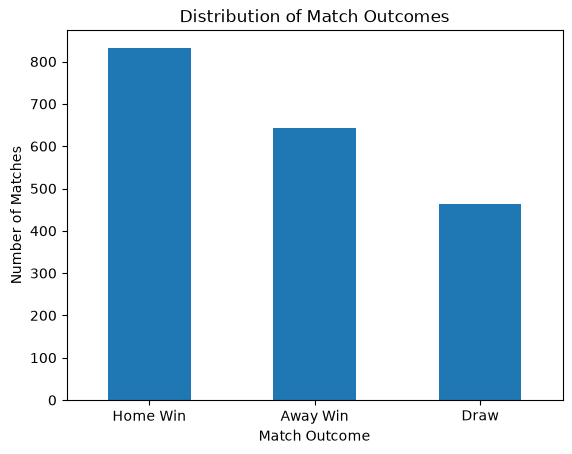

In [235]:
import matplotlib.pyplot as plt
counts = df_clean["match_outcome"].value_counts()

counts.plot(kind="bar")

plt.title("Distribution of Match Outcomes")
plt.xlabel("Match Outcome")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.show()

Home wins were the most common match outcome, occurring 832 times, followed by 644 away wins and 463 draws. This suggests that home teams may have an advantage because they won more frequently than away teams. Further analysis is needed to understand whether this pattern is consistent across different leagues.

##Home Goals Distribution

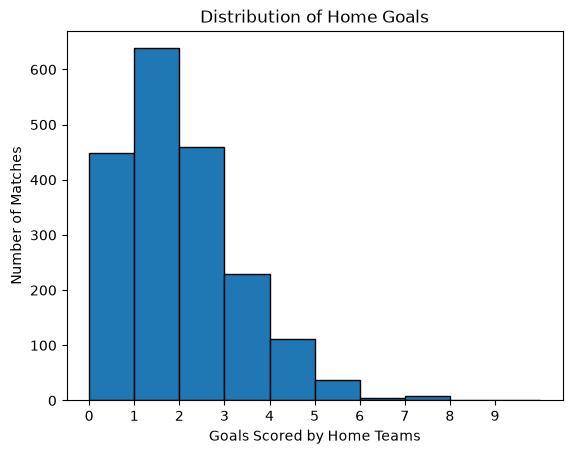

count    1939.000000
mean        1.537390
std         1.322591
min         0.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         9.000000
Name: fulltime_home, dtype: float64
fulltime_home
0    448
1    638
2    460
3    229
4    112
5     37
6      5
7      8
8      1
9      1
Name: count, dtype: int64


In [236]:
goals = df_clean["fulltime_home"]

goals.plot(kind="hist", bins=range(goals.max() + 2), edgecolor="black")

plt.title("Distribution of Home Goals")
plt.xlabel("Goals Scored by Home Teams")
plt.ylabel("Number of Matches")
plt.xticks(range(goals.max() + 1))
plt.show()

print(df_clean["fulltime_home"].describe())
print(df_clean["fulltime_home"].value_counts().sort_index())

Home teams scored an average of 1.54 goals per match, with a median of 1 goal. The distribution is right-skewed, meaning most matches had relatively few home goals, while higher goal counts were less common. Goals ranged from 0 to 9, with only 15 matches having 6 or more home goals. Comparing this distribution with away goals can help us investigate whether playing at home is associated with better scoring performance.

## Away Goals Distribution

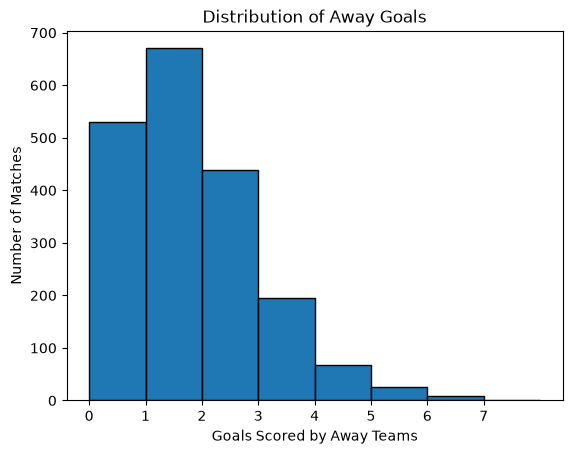

count    1939.000000
mean        1.339350
std         1.206002
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max         7.000000
Name: fulltime_away, dtype: float64
fulltime_away
0    531
1    670
2    438
3    196
4     68
5     26
6      9
7      1
Name: count, dtype: int64


In [237]:
goals = df_clean["fulltime_away"]

goals.plot(kind="hist", bins=range(goals.max() + 2), edgecolor="black")

plt.title("Distribution of Away Goals")
plt.xlabel("Goals Scored by Away Teams")
plt.ylabel("Number of Matches")
plt.xticks(range(goals.max() + 1))
plt.show()

print(goals.describe())
print(goals.value_counts().sort_index())

Away teams scored an average of 1.34 goals per match, with a median of 1 goal. The distribution is right-skewed, meaning most away teams scored relatively few goals, while higher goal counts were less common. Goals ranged from 0 to 7, with only 10 matches having 6 or more away goals. Compared to home teams, which averaged 1.54 goals, away teams scored fewer goals on average.

## Goal Difference Distribution

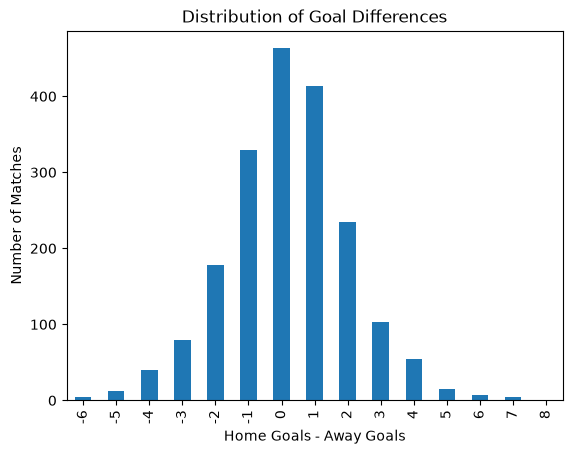

count    1939.000000
mean        0.198040
std         1.880314
min        -6.000000
25%        -1.000000
50%         0.000000
75%         1.000000
max         8.000000
Name: goal_difference, dtype: float64


In [238]:
df_clean["goal_difference"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Goal Differences")
plt.xlabel("Home Goals - Away Goals")
plt.ylabel("Number of Matches")
plt.show()

print(df_clean["goal_difference"].describe())

The average goal difference was approximately +0.20 goals, while the median was 0. Most matches had goal differences close to zero, indicating that many matches were relatively close. Goal differences ranged from -6 to +8, with large differences being uncommon. The slightly positive average suggests that home teams generally scored more goals than away teams, which may indicate a home-field advantage.

## Competition Distribution

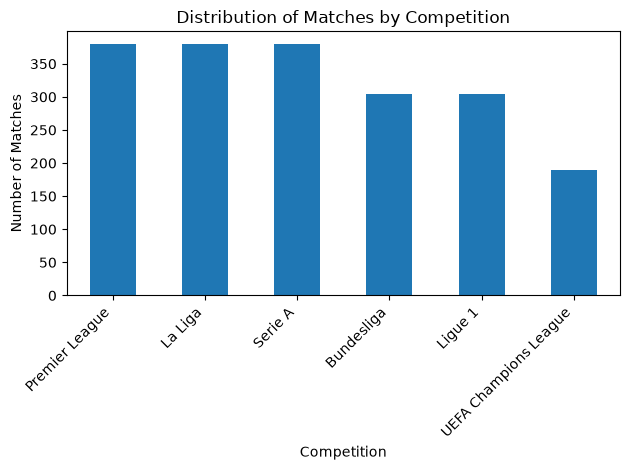

In [239]:
df_clean["competition_name"].value_counts().plot(kind="bar")

plt.title("Distribution of Matches by Competition")
plt.xlabel("Competition")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The Premier League, La Liga, and Serie A each contain 380 matches, while the Bundesliga and Ligue 1 each contain 305 matches. The Champions League has the fewest matches, with 189. Since the competitions have different numbers of matches, comparing raw home-win counts could be misleading. Therefore, comparing home-win percentages across competitions will help us investigate whether home advantage differs between them.

## 4. Relationships Between Home-Win Percentage Across Competitions

competition_name
Bundesliga               38.69
La Liga                  44.47
Ligue 1                  46.89
Premier League           40.79
Serie A                  39.74
UEFA Champions League    50.79
Name: match_outcome, dtype: float64


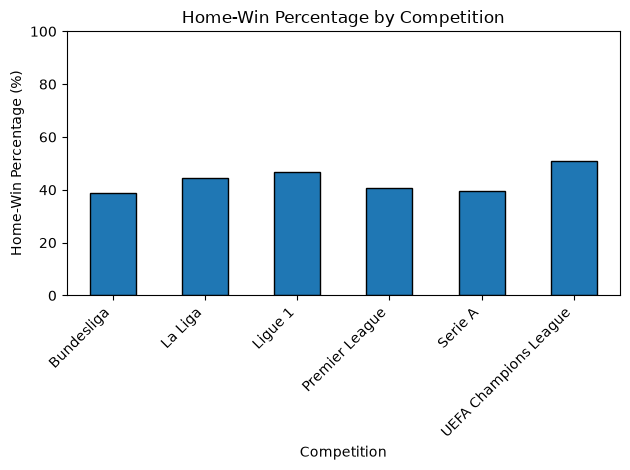

In [240]:
home_win_pct = df_clean.groupby("competition_name")["match_outcome"].apply(
    lambda x: (x == "Home Win").mean() * 100
)

print(home_win_pct.round(2))

home_win_pct.plot(kind="bar", edgecolor="black")

plt.title("Home-Win Percentage by Competition")
plt.xlabel("Competition")
plt.ylabel("Home-Win Percentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 5. So what/Expected?
Home-win percentages differed across competitions, with the Champions League highest and Bundesliga lowest. This tells us that home teams don't win at the same frequency in every competition. I expected home-win percentages to vary somewhat across competitions because teams and playing conditions differ. However, I was surprised by the size of the difference, with the Champions League having the highest home-win percentage at 50.79% and the Bundesliga the lowest at 38.69%.

## 6. What Next?
Next, I would compare home-win, away-win, and draw percentages within each competition to see whether home teams actually have a stronger advantage in certain leagues. This would help determine whether the differences in home-win percentages reflect home-field advantage or are partly explained by differences in draw rates. So, our original research question was: How does playing at home affect team performance and match outcomes? Based on these findings, I would restate our research question as: How does home-field advantage vary across European football competitions when comparing home-win, away-win, and draw percentages?